# R Installation and VS Code Setup

To run the R language, it must be installed on your computer.
VS Code cannot run R on its own, so you first need to install R and then integrate it with VS Code.

These steps make it easier to write and run R scripts, and enable features like auto-completion, linting and inline plots. By the end of this lesson you will have a working **R + VS Code + Jupyter** setup and you will have verified it from inside this very notebook.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Installing R

* Download the version suitable for your operating system from the official R site: [CRAN R](https://cran.r-project.org/)
* During installation, **add R to your system PATH** (Windows usually does this automatically, but it's still good to check in your system environment variables).
* **Linux (Debian/Ubuntu):** `sudo apt install r-base r-base-dev`
* **macOS (Homebrew):** `brew install --cask r`

To verify the installation, run the following command in Terminal or CMD/PowerShell:

```bash
R --version
```

If you see the R version information, the installation was successful.

## 2. Installing VS Code

* If VS Code is not installed: [Visual Studio Code](https://code.visualstudio.com/)
* Optional but recommended: **RStudio** ([posit.co](https://posit.co/download/rstudio-desktop/)) is the classic R IDE. Everything in this section runs in either tool.

## 3. Required Extensions

In the VS Code **Extensions** panel, install the following:

1. **R** (Author: REditorSupport) – R language support and syntax highlighting.
2. **R Debugger** (Author: REditorSupport) – Debugging support for R scripts.
3. **Jupyter** (Author: Microsoft) – Runs `.ipynb` notebooks such as this one.

## 4. Configuring VS Code for R

### a) Terminal Settings

* In VS Code, press **Ctrl + Shift + P** → search for `"Preferences: Open Settings (JSON)"`.
* For Windows:

```json
"r.rterm.windows": "C:\\Program Files\\R\\R-4.3.1\\bin\\R.exe"
```

* For Mac/Linux:

```json
"r.rterm.mac": "/usr/local/bin/R",
"r.rterm.linux": "/usr/bin/R"
```

### b) R Language Server

* In VS Code, open **Terminal** → **New Terminal**.
* Type `R` to start the R console.
* In the R console, install the package:

```r
install.packages("languageserver")
```

This package enables VS Code to provide auto-completion, error checking, and code analysis for R.

## 5. Running R Scripts

* Create a new file with the `.R` extension.
* Open the terminal (**Ctrl + \`**) and run R commands there.
* Alternatively, select code lines and press **Ctrl + Enter** to run them directly in the terminal.

## 6. Using R in Jupyter Notebook

* First, install the `IRkernel` package in R:

```r
install.packages("IRkernel")
IRkernel::installspec()  # Registers R as a kernel in Jupyter
```

* If you don't have Jupyter Notebook or JupyterLab installed, run in your terminal:

```bash
pip install notebook      # or: pip install jupyterlab
```

* Once installed, launch Jupyter with `jupyter notebook` (or `jupyter lab`).

From the "Select Kernel" menu, choose **R** to run R code in `.ipynb` notebooks cell-by-cell.

> **Troubleshooting (Windows):** if you see *"The kernel 'R' was not started as it is located in an insecure location 'c:\ProgramData\jupyter\kernels\ir\kernel.json'"*, open VS Code Settings, search for `jupyter.kernels.trusted` and add `C:\ProgramData\jupyter\kernels\ir\kernel.json`.

## 7. Verify Your Setup From This Notebook

If the kernel picker shows **R** and the cell below runs, your setup works. It prints the R version, where packages get installed, and whether the packages used later in this section are already available.

In [2]:
cat("R version      :", R.version.string, "\n")
cat("Platform       :", R.version$platform, "\n")
cat("Library paths  :", paste(.libPaths(), collapse = " | "), "\n\n")

# Packages used later in Section 02
needed <- c("Deriv", "car", "rstatix", "effsize", "ez", "scatterplot3d",
            "DiagrammeR", "DiagrammeRsvg", "rsvg", "ggplot2", "pROC")
status <- data.frame(package = needed,
                     installed = suppressMessages(sapply(needed, requireNamespace, quietly = TRUE)),
                     row.names = NULL)
print(status)

missing <- status$package[!status$installed]
if (length(missing) > 0) {
  cat("\nInstall the missing ones with:\ninstall.packages(c(",
      paste0('"', missing, '"', collapse = ", "), "))\n")
} else {
  cat("\nAll packages for this section are installed.\n")
}

R version      : R version 4.5.3 (2026-03-11) 


Platform       : x86_64-pc-linux-gnu 


Library paths  : /usr/local/lib/R/site-library | /usr/lib/R/site-library | /usr/lib/R/library 



         package installed
1          Deriv      TRUE
2            car      TRUE
3        rstatix      TRUE
4        effsize      TRUE
5             ez      TRUE
6  scatterplot3d      TRUE
7     DiagrammeR     FALSE
8  DiagrammeRsvg     FALSE
9           rsvg     FALSE
10       ggplot2      TRUE
11          pROC      TRUE



Install the missing ones with:
install.packages(c( "DiagrammeR", "DiagrammeRsvg", "rsvg" ))


## 8. A First Plot (Sanity Check for Graphics)

Plots are rendered inline. If you see the chart below, the graphics device works too.

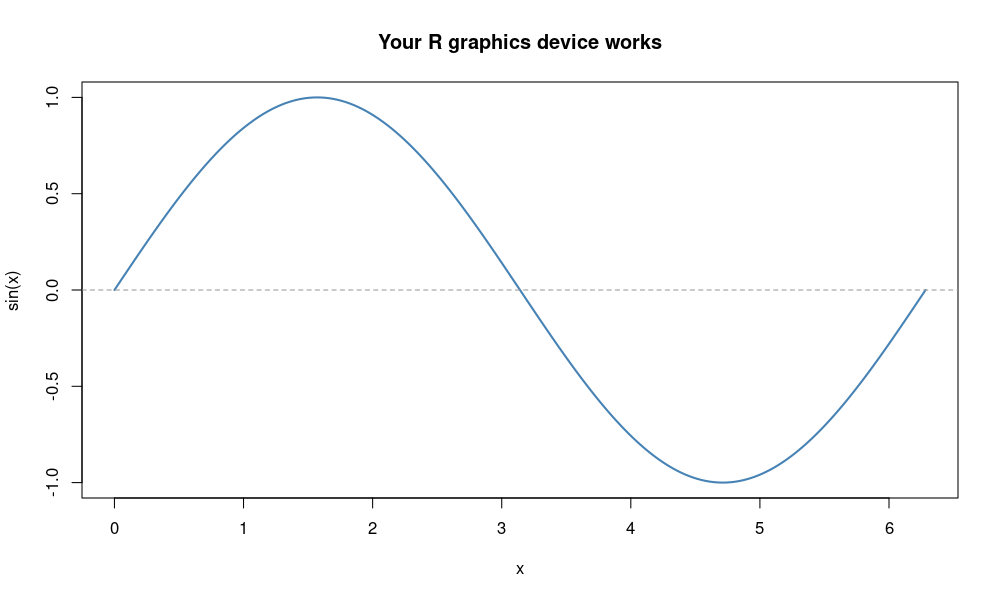

In [3]:
x <- seq(0, 2 * pi, length.out = 200)
plot(x, sin(x), type = "l", lwd = 2, col = "steelblue",
     main = "Your R graphics device works", xlab = "x", ylab = "sin(x)")
abline(h = 0, col = "grey60", lty = 2)

*Insight: Most "R doesn't work" problems are actually PATH or kernel-registration problems. If `R --version` works in a terminal but the notebook can't find R, re-run `IRkernel::installspec()` from the R console you actually want Jupyter to use.*

## Real-World Use Case or Analogy

Setting up R is like **setting up a new kitchen**:

* **R** is the stove: it does the actual cooking (computation).
* **VS Code / RStudio** is the countertop where you prepare and organise ingredients (code).
* **IRkernel + Jupyter** is the recipe book that lets you write instructions and see the finished dish (output) on the same page.
* **Packages** are specialised tools (a blender, a pasta maker): you install them once and pull them out with `library()` whenever a recipe needs them.

Every analyst on a team needs the same "kitchen" so that a recipe written by one person produces the same dish for everyone else — which is exactly what a reproducible R setup gives you.